# Step 0: Slicing (kritikaa, patient 22, tumour)

Creates the 2D slices and masks I use later. They are saved in `data/slices/kritikaa/` already.

In [1]:
import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import cv2

PATIENT = 22          # this member's patient
NAME = "kritikaa"      # this member's slices folder
RAW = "../data/raw_volumes"
OUT = "../data/slices/" + NAME

## Step 1: Load the volume

CT volume in HU and the label volume.

In [2]:
# load the 3D CT volume (HU) and its mask
vol = nib.load(RAW + "/volume-" + str(PATIENT) + ".nii.gz").get_fdata()        # CT, values in HU
seg = nib.load(RAW + "/segmentation-" + str(PATIENT) + ".nii.gz").get_fdata()  # 0 bg, 1 liver, 2 tumour
print("shape:", vol.shape, seg.shape)
print("HU range:", vol.min(), "to", vol.max())
print("labels in mask:", np.unique(seg))

shape: (512, 512, 247) (512, 512, 247)
HU range: -3024.0 to 3071.0


labels in mask: [0. 1. 2.]


## Step 2: Show a slice and its histogram

The slices come out sideways, so I use rot90.

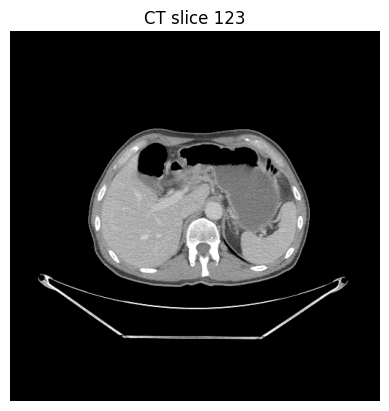

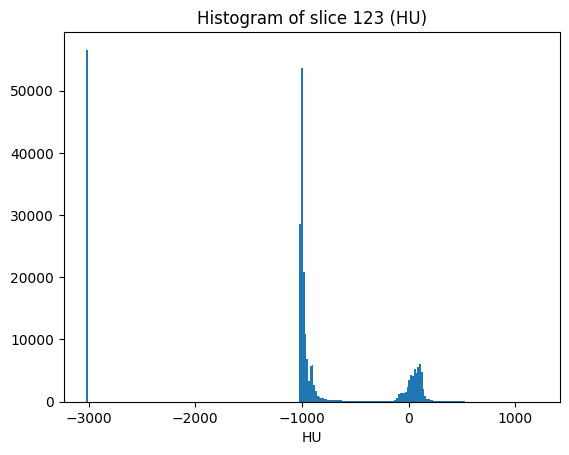

In [3]:
# show the middle slice (rot90 fixes the sideways orientation)
middle = vol.shape[2] // 2
plt.figure()
plt.imshow(np.rot90(vol[:, :, middle]), cmap='gray', vmin=-200, vmax=250)
plt.title('CT slice ' + str(middle))
plt.axis('off')
plt.show()

# look at the histogram of the HU values: air near -1000, soft tissue near 0 to 100, bone above 300
plt.figure()
plt.hist(vol[:, :, middle].ravel(), bins=256)
plt.title('Histogram of slice ' + str(middle) + ' (HU)')
plt.xlabel('HU')
plt.show()

## Step 3: Find the tumour slices

My target is the tumour, so I keep the slices with label 2.

In [4]:
# find every slice that contains tumour (label 2)
tumour_slices = []
for i in range(seg.shape[2]):
    if np.any(seg[:, :, i] == 2):
        tumour_slices.append(i)
print(len(tumour_slices), "tumour slices:", tumour_slices)

12 tumour slices: [126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137]


## Step 4: Save them

Raw HU (`.npy`) with a liver mask and a tumour mask.

saved 12 slices to ../data/slices/kritikaa


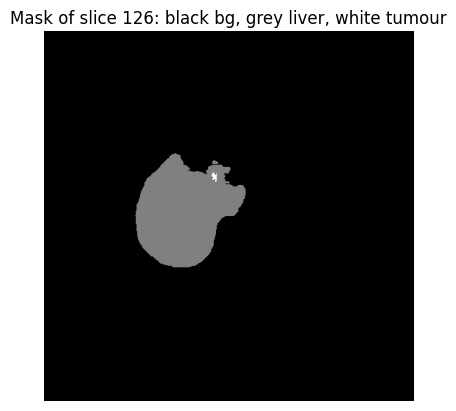

In [5]:
# save every tumour slice: CT (HU) as .npy, liver and tumour masks as black/white .png
chosen = tumour_slices          # all tumour slices (they also contain liver)
os.makedirs(OUT, exist_ok=True)
for i in chosen:
    ct = np.rot90(vol[:, :, i])
    s = np.rot90(seg[:, :, i])
    base = OUT + "/p" + str(PATIENT) + "_s" + str(i)
    np.save(base + "_ct.npy", ct.astype(np.float32))                       # raw HU values
    cv2.imwrite(base + "_liver.png", ((s >= 1) * 255).astype(np.uint8))    # white = liver
    cv2.imwrite(base + "_tumour.png", ((s == 2) * 255).astype(np.uint8))   # white = tumour
print("saved", len(chosen), "slices to", OUT)

# show the first saved slice and its masks
i = chosen[0]
plt.figure()
plt.imshow(np.rot90(seg[:, :, i]), cmap='gray')
plt.title('Mask of slice ' + str(i) + ': black bg, grey liver, white tumour')
plt.axis('off')
plt.show()

## Step 5: Tumour-free slices

Up to 6 slices without tumour (at least 3000 liver pixels, at least 3 slices away from any tumour) are saved in `data/slices/<name>_healthy/` to test for false alarms.

In [6]:
HEALTHY_OUT = "../data/slices/" + NAME + "_healthy"
MIN_LIVER_PX = 3000
GAP = 3
N_HEALTHY = 6

# liver slices that are big enough (no tiny pole slices)
liver_ok = []
for i in range(seg.shape[2]):
    if (seg[:, :, i] >= 1).sum() >= MIN_LIVER_PX:
        liver_ok.append(i)

# keep only those with no tumour within 3 slices
free = []
for i in liver_ok:
    far_from_tumour = True
    for t in tumour_slices:
        if abs(i - t) < GAP:
            far_from_tumour = False
    if far_from_tumour:
        free.append(i)

# up to 6 slices spread evenly over the free ones
positions = np.linspace(0, len(free) - 1, min(N_HEALTHY, len(free)))
picks = np.unique(positions.round().astype(int))
healthy_slices = []
for j in picks:
    healthy_slices.append(free[j])

os.makedirs(HEALTHY_OUT, exist_ok=True)
for i in healthy_slices:
    ct = np.rot90(vol[:, :, i])
    s = np.rot90(seg[:, :, i])
    base = HEALTHY_OUT + "/p" + str(PATIENT) + "_s" + str(i)
    np.save(base + "_ct.npy", ct.astype(np.float32))
    cv2.imwrite(base + "_liver.png", ((s >= 1) * 255).astype(np.uint8))
    cv2.imwrite(base + "_tumour.png", ((s == 2) * 255).astype(np.uint8))      # all black: no tumour
print(len(free), "usable tumour-free liver slices; saved", healthy_slices, "to", HEALTHY_OUT)

18 usable tumour-free liver slices; saved [112, 115, 119, 122, 142, 145] to ../data/slices/kritikaa_healthy
